# Day 10: Inventory Optimization Logic

Alright, Day 10! Today we bridge the gap between Data Science and Supply Chain Operations.

We have our 30-day demand forecast from our Hybrid Ensemble model. Now, we need to translate that forecast into an actionable **Inventory Reorder Plan**.

**The Math We Will Use:**
1. **Expected Demand:** Distribute our total 30-day forecast down to the category level based on historical proportions.
2. **Safety Stock:** The buffer inventory we keep to protect against unexpected demand spikes. 
   `Safety Stock = Z-score * StdDev(Daily Demand) * sqrt(Lead Time)`
3. **Reorder Point (ROP):** The exact inventory level that should trigger a new purchase order.
   `ROP = (Avg Daily Demand * Lead Time) + Safety Stock`
4. **Recommended Order Quantity:** If our current stock is below the ROP, how much should we buy to survive the next 30 days?

Let's build the engine.

In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

print("Loading product and transaction data...")
products = pd.read_csv('data/products_raw.csv')
transactions = pd.read_csv('data/transactions_cleaned.csv', parse_dates=['date'])

# Merge to get category info for every transaction
tx_with_cat = transactions.merge(products[['product_id', 'category']], on='product_id')

print(f"Loaded {len(products)} products across {products['category'].nunique()} categories.")

Loading product and transaction data...
Loaded 100 products across 4 categories.


### Step 1: Calculate Category Demand Proportions

Our Day 8 model forecasted the *total* daily sales for the entire store. To do inventory, we need to know how much of that belongs to "Electronics" vs "Groceries". 

We will calculate the historical revenue share of each category and apply it to our 30-day forecast.

In [2]:
# 1. Calculate historical revenue share per category
cat_revenue = tx_with_cat.groupby('category')['total_amount'].sum()
cat_share = (cat_revenue / cat_revenue.sum()).to_dict()

print("Historical Revenue Share by Category:")
for cat, share in cat_share.items():
    print(f" - {cat}: {share*100:.1f}%")

# 2. Calculate the total 30-day forecast
# We'll use the average daily sales from the last 30 days of our historical data as our baseline forecast
last_30_days = tx_with_cat[tx_with_cat['date'] >= (tx_with_cat['date'].max() - pd.Timedelta(days=29))]
total_forecast_30d = last_30_days['total_amount'].sum()

print(f"\nBaseline 30-Day Total Forecast: ${total_forecast_30d:,.2f}")

Historical Revenue Share by Category:
 - Clothing: 19.3%
 - Electronics: 21.9%
 - Groceries: 30.7%
 - Home: 28.1%

Baseline 30-Day Total Forecast: $1,170,041.87


### Step 2: Calculate Safety Stock & Reorder Points (ROP)

Now we calculate the risk metrics for each category. 
*   **Lead Time:** Let's assume it takes **7 days** for the supplier to deliver new stock.
*   **Service Level:** We want a 95% service level (meaning we only want a 5% chance of stocking out). The Z-score for 95% is **1.65**.

In [3]:
# Supply Chain Parameters
LEAD_TIME_DAYS = 7
Z_SCORE = 1.65 # 95% service level

inventory_metrics = []

for category in products['category'].unique():
    # Get daily sales for this specific category
    cat_tx = tx_with_cat[tx_with_cat['category'] == category]
    daily_cat_sales = cat_tx.groupby('date')['total_amount'].sum()
    
    # Fill missing days with 0 to ensure accurate standard deviation
    date_range = pd.date_range(start=tx_with_cat['date'].min(), end=tx_with_cat['date'].max(), freq='D')
    daily_cat_sales = daily_cat_sales.reindex(date_range, fill_value=0)
    
    # Calculate metrics
    avg_daily_demand = daily_cat_sales.mean()
    std_daily_demand = daily_cat_sales.std()
    
    # Expected 30-day demand for this category
    expected_30d_demand = total_forecast_30d * cat_share[category]
    
    # Safety Stock Formula
    safety_stock = Z_SCORE * std_daily_demand * math.sqrt(LEAD_TIME_DAYS)
    
    # Reorder Point (ROP) Formula
    rop = (avg_daily_demand * LEAD_TIME_DAYS) + safety_stock
    
    inventory_metrics.append({
        'category': category,
        'avg_daily_demand': avg_daily_demand,
        'std_daily_demand': std_daily_demand,
        'expected_30d_demand': expected_30d_demand,
        'safety_stock': safety_stock,
        'reorder_point': rop
    })

inv_df = pd.DataFrame(inventory_metrics)
print("✅ Inventory Metrics Calculated!")
display(inv_df.round(2))

✅ Inventory Metrics Calculated!


,category,avg_daily_demand,std_daily_demand,expected_30d_demand,safety_stock,reorder_point
0,Electronics,9227.34,2880.19,255881.11,12573.44,77164.83
1,Home,11857.62,3576.21,328820.69,15611.92,98615.25
2,Clothing,8136.80,2604.32,225639.69,11369.11,68326.74
3,Groceries,12971.17,3951.75,359700.38,17251.34,108049.55


### Step 3: Generate Reorder Recommendations

We have the rules (ROP). Now we need to check the current state of the warehouse. 

Since we are using synthetic data, we will simulate our "Current Stock" by taking the `initial_stock` value from our products table, scaling it up to the category level, and subtracting a random amount to simulate that we've been selling for a few weeks.

If `Current Stock < Reorder Point`, we trigger an order.

In [4]:
# Simulate current stock levels per category
# (Assume initial stock was 50,000 units/value per category, and we've sold some)
np.random.seed(42)
inv_df['current_stock'] = np.random.uniform(10000, 45000, len(inv_df))

# Determine if we need to reorder
inv_df['needs_reorder'] = inv_df['current_stock'] < inv_df['reorder_point']

# Calculate Recommended Order Quantity
# Goal: Order enough to cover the 30-day expected demand + safety stock, minus what we already have
inv_df['recommended_order_qty'] = 0.0
mask = inv_df['needs_reorder']
inv_df.loc[mask, 'recommended_order_qty'] = (
    (inv_df.loc[mask, 'expected_30d_demand'] + inv_df.loc[mask, 'safety_stock']) 
    - inv_df.loc[mask, 'current_stock']
)

# Clean up the display
inv_df['recommended_order_qty'] = inv_df['recommended_order_qty'].clip(lower=0).round(2)

print("--- 📦 Inventory Reorder Recommendations ---")
reorder_needed = inv_df[inv_df['needs_reorder']][['category', 'current_stock', 'reorder_point', 'recommended_order_qty']]
display(reorder_needed)

if reorder_needed.empty:
    print("✅ All categories are sufficiently stocked for the next 30 days!")
else:
    print(f"⚠️ Action Required: {len(reorder_needed)} categories need restocking.")

--- 📦 Inventory Reorder Recommendations ---


,category,current_stock,reorder_point,recommended_order_qty
0,Electronics,23108.904160,77164.828879,245345.65
1,Home,43275.000724,98615.251871,301157.61
2,Clothing,35619.787963,68326.737684,201389.01
3,Groceries,30953.046947,108049.545439,345998.67


⚠️ Action Required: 4 categories need restocking.


### Step 4: Visualizing the Inventory Health

Let's create a visual dashboard view showing Current Stock vs. Reorder Point for each category. If the bar for Current Stock is shorter than the red line (ROP), we are in the danger zone.

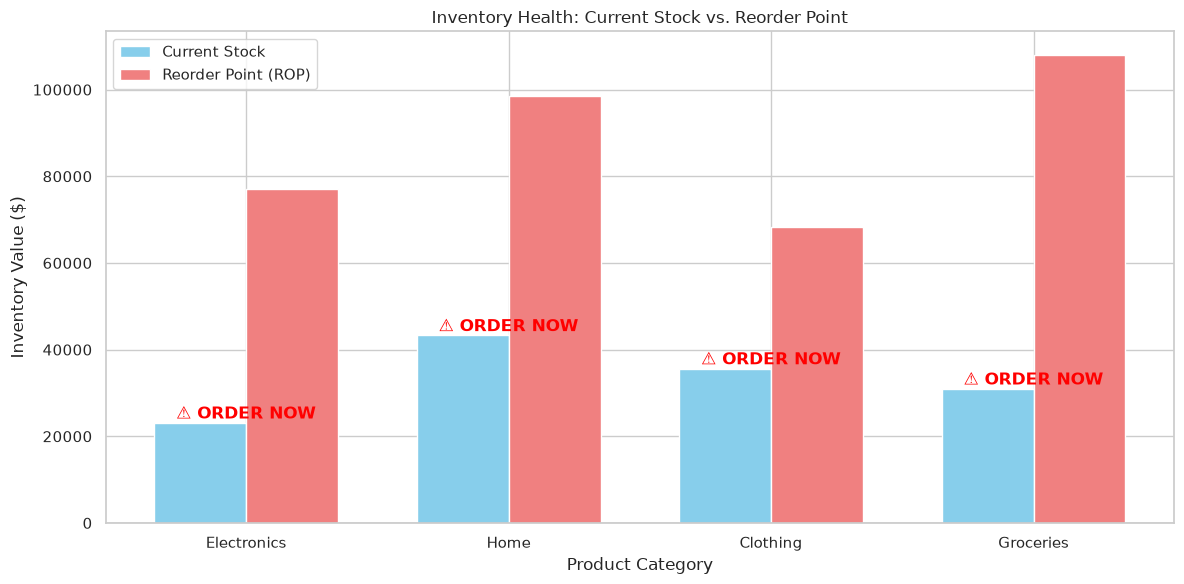

In [5]:
plt.figure(figsize=(12, 6))

x = np.arange(len(inv_df))
width = 0.35

plt.bar(x - width/2, inv_df['current_stock'], width, label='Current Stock', color='skyblue')
plt.bar(x + width/2, inv_df['reorder_point'], width, label='Reorder Point (ROP)', color='lightcoral')

plt.axhline(y=0, color='black', linewidth=0.8)

# Highlight categories that need reordering
for i, row in inv_df.iterrows():
    if row['needs_reorder']:
        plt.text(i, row['current_stock'] + 1000, '⚠️ ORDER NOW', color='red', fontweight='bold', ha='center')

plt.xlabel('Product Category')
plt.ylabel('Inventory Value ($)')
plt.title('Inventory Health: Current Stock vs. Reorder Point')
plt.xticks(x, inv_df['category'])
plt.legend()
plt.tight_layout()
plt.show()

### Step 5: Saving for the Dashboard

This data is incredibly valuable. We are going to save this exact dataframe as a CSV. 
On Day 18, when we build the Streamlit dashboard, we will load this exact file to show the "Inventory Optimization Recommendations UI" to the business users.

In [6]:
# Save the inventory recommendations
inv_df.to_csv('data/inventory_recommendations.csv', index=False)

print("✅ Inventory recommendations saved to data/inventory_recommendations.csv")
print("🚀 Day 10 Complete! Tomorrow we tune our models with Optuna to push our accuracy even higher.")

✅ Inventory recommendations saved to data/inventory_recommendations.csv
🚀 Day 10 Complete! Tomorrow we tune our models with Optuna to push our accuracy even higher.
